# 04 SHAP

This notebook looks at what the final model relies on, using validation rows only. The model is read from `reports/final_model.json`, which `02_tuning` writes. SHAP values come from LightGBM itself (`pred_contrib=True`), averaged over the 5 seeds.

A SHAP value says how much one feature moves one climber's log-odds of reaching the summit compared with the average prediction. Features that carry the same information share the credit, so we also measure groups together, for example all the crowding columns. SHAP describes what the model learned and does not show that a feature causes success.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import log_loss, roc_auc_score

from src import models as M
from src.config import TABLES_DIR
from src.explain import (FEATURE_GROUPS, binned_effect, category_effect, group_importance, importance,
                         raw_scores, shap_values)
from src.features import to_number
from src.split import dev_split, fit_frame, load_features
from src.style import BLUE, DARK_BLUE, GRID, INK, apply_style, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
apply_style()

## 1. The frozen model

In [2]:
final = M.load_final_config()
train, val = dev_split(load_features())
train_fit = fit_frame(train)
model = M.refit_lightgbm(train_fit, final["iterations"], params=final["params"], features=final["features"], seeds=tuple(final["seeds"]))
y_val, p_val = M.target(val), model.predict(val)
print(f"LightGBM, {final['iterations']} trees, {len(final['seeds'])} seeds, {len(final['features'])} features")
print(f"val rows {len(val):,}: AUC {roc_auc_score(y_val, p_val):.3f}, log loss {log_loss(y_val, p_val):.3f}, mean p {p_val.mean():.3f}, success rate {y_val.mean():.3f}")

LightGBM, 176 trees, 5 seeds, 34 features
val rows 5,042: AUC 0.712, log loss 0.622, mean p 0.496, success rate 0.537


## 2. SHAP values
Two checks first: the SHAP values of a row have to add up to its raw prediction, and one dominant feature would point to leakage.

In [3]:
shap, base = shap_values(model, val)
BASE = float(base.mean())
gap = np.abs(shap.sum(axis=1).to_numpy() + base - raw_scores(model, val)).max()
assert gap < 1e-6
by_feature, by_group = importance(shap), group_importance(shap)
print(f"largest additivity gap: {gap:.2e}")
print(f"average prediction: log-odds {BASE:.3f}, probability {1 / (1 + np.exp(-BASE)):.3f}")
print(f"top feature: {by_feature.index[0]}, {by_feature.iloc[0] / by_feature.sum():.1%} of all mean |SHAP|")
by_feature.rename("mean_abs_shap").to_csv(TABLES_DIR / "04_shap_features.csv")
by_group.rename("mean_abs_shap").to_csv(TABLES_DIR / "04_shap_groups.csv")
display(by_feature.head(15).round(3).to_frame("mean |SHAP|"))
display(by_group.round(3).to_frame("mean |SHAP|"))

largest additivity gap: 2.00e-15
average prediction: log-odds -0.549, probability 0.366
top feature: CROWD_ROUTE, 11.6% of all mean |SHAP|


,mean |SHAP|
CROWD_ROUTE,0.224
PRIOR_SUMMITS,0.206
CALCAGE,0.197
CITIZEN,0.179
HIRED_PER_MEMBER,0.163
PEAK_SUCCESS_PRIOR,0.136
CROWD_ROUTE_TOTAL,0.102
HEIGHTM,0.091
ROUTE1,0.083
AGENCY,0.082


,mean |SHAP|
Crowding,0.427
Peak and route,0.272
Experience,0.265
Age,0.197
Hired staff and team size,0.185
Person,0.180
Agency,0.082
Season,0.015


## 3. Importance

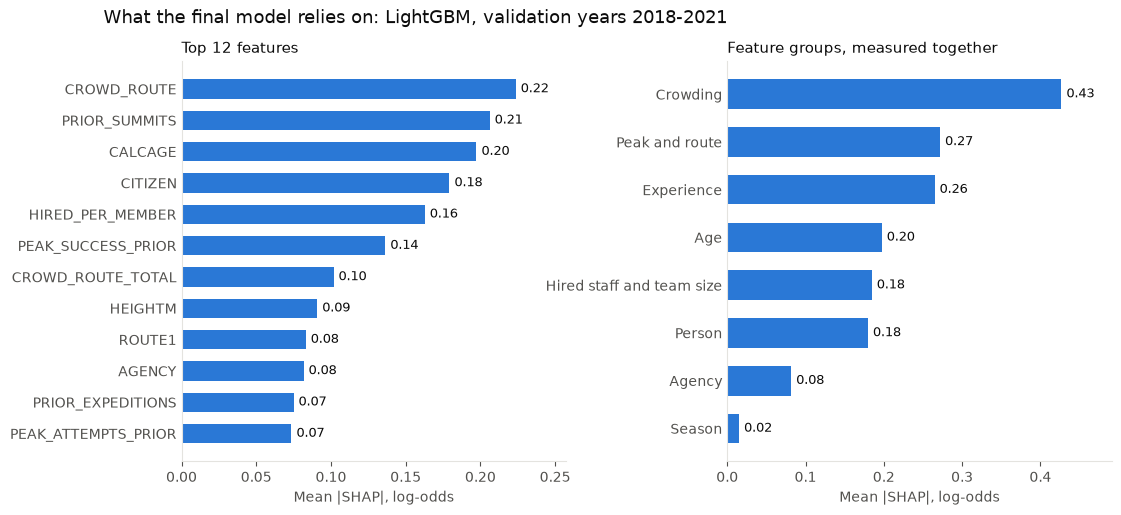

In [4]:
def bars(ax, values, title):
    values = values.sort_values()
    y = np.arange(len(values))
    ax.barh(y, values.to_numpy(), height=0.62, color=BLUE)
    ax.set_yticks(y, values.index)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Mean |SHAP|, log-odds")
    ax.set_xlim(0, values.max() * 1.15)
    ax.tick_params(axis="y", length=0)
    for yy, value in zip(y, values.to_numpy()):
        ax.text(value + values.max() * 0.015, yy, f"{value:.2f}", va="center", color=INK, fontsize=9)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"wspace": 0.42})
bars(left, by_feature.head(12), "Top 12 features")
bars(right, by_group, "Feature groups, measured together")
fig.suptitle("What the final model relies on: LightGBM, validation years 2018-2021", x=0.06, ha="left", fontsize=13, color=INK)
save_figure(fig, "04_shap_importance.png")
plt.show()

## 4. Shape of the main effects
Each dot is a climber in the validation years and the line is the mean effect in each bin. For experience, hired staff and crowding the effect is summed over the group, since those columns carry the same information. All panels use the same vertical scale.

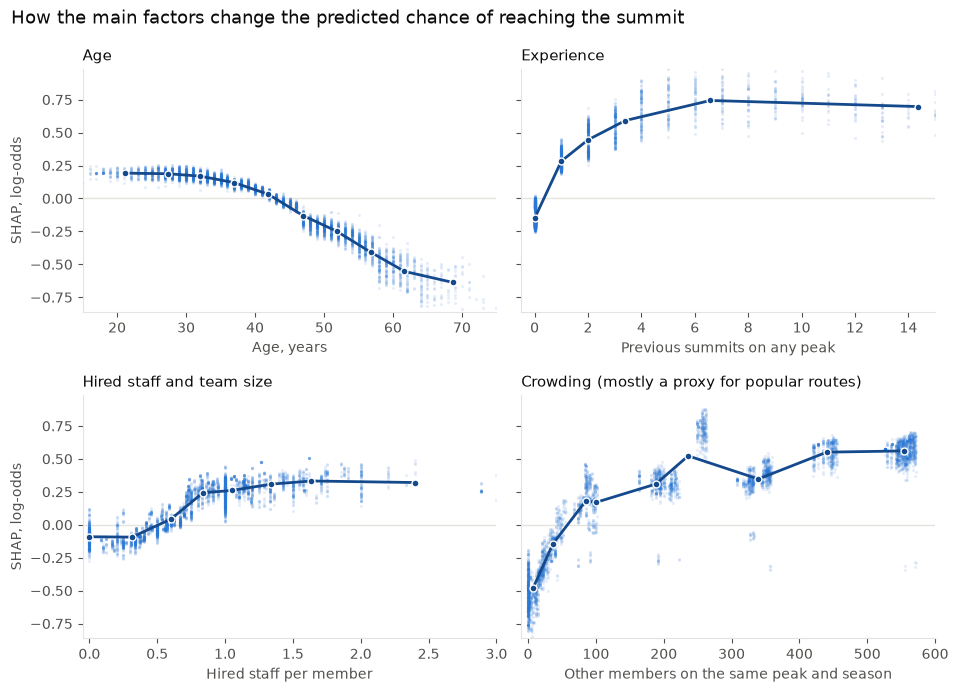

Age


,n,x_mean,shap_mean,points
"[0, 25)",228,21.096,0.192,4.563
"[25, 30)",434,27.399,0.188,4.451
"[30, 35)",677,31.999,0.170,4.017
"[35, 40)",773,36.920,0.121,2.850
"[40, 45)",741,41.926,0.032,0.741
"[45, 50)",709,46.969,-0.130,-2.962
"[50, 55)",652,51.824,-0.248,-5.551
"[55, 60)",449,56.746,-0.407,-8.835
"[60, 65)",221,61.665,-0.553,-11.680
"[65, 100)",104,68.702,-0.637,-13.218


Experience


,n,x_mean,shap_mean,points
"[0, 1)",3137,0.000,-0.151,-3.429
"[1, 2)",798,1.000,0.283,6.789
"[2, 3)",330,2.000,0.445,10.790
"[3, 5)",290,3.397,0.591,14.448
"[5, 10)",244,6.582,0.744,18.238
"[10, 100)",179,14.374,0.697,17.089


Hired staff and team size


,n,x_mean,shap_mean,points
"[0.0, 0.01)",613,0.000,-0.091,-2.086
"[0.01, 0.5)",818,0.315,-0.094,-2.148
"[0.5, 0.75)",993,0.602,0.044,1.020
"[0.75, 1.0)",617,0.835,0.242,5.768
"[1.0, 1.25)",1256,1.049,0.261,6.230
"[1.25, 1.5)",318,1.341,0.308,7.402
"[1.5, 2.0)",292,1.637,0.332,7.991
"[2.0, 10.0)",135,2.399,0.320,7.701


Crowding (mostly a proxy for popular routes)


,n,x_mean,shap_mean,points
"[0, 25)",1163,7.396,-0.480,-10.276
"[25, 50)",350,36.506,-0.146,-3.319
"[50, 100)",515,85.163,0.182,4.315
"[100, 150)",26,100.538,0.171,4.042
"[150, 200)",386,188.212,0.309,7.411
"[200, 300)",474,236.049,0.523,12.735
"[300, 400)",669,339.347,0.347,8.362
"[400, 500)",409,440.342,0.551,13.441
"[500, 1000)",1050,553.770,0.560,13.670


In [5]:
PANELS = [
    ("Age", "CALCAGE", FEATURE_GROUPS["Age"], [0, 25, 30, 35, 40, 45, 50, 55, 60, 65, 100], (15, 75), "Age, years"),
    ("Experience", "PRIOR_SUMMITS", FEATURE_GROUPS["Experience"], [0, 1, 2, 3, 5, 10, 100], (-0.5, 15), "Previous summits on any peak"),
    ("Hired staff and team size", "HIRED_PER_MEMBER", FEATURE_GROUPS["Hired staff and team size"], [0, 0.01, 0.5, 0.75, 1, 1.25, 1.5, 2, 10], (-0.05, 3), "Hired staff per member"),
    ("Crowding (mostly a proxy for popular routes)", "CROWD_PEAK", FEATURE_GROUPS["Crowding"], [0, 25, 50, 100, 150, 200, 300, 400, 500, 1000], (-10, 600), "Other members on the same peak and season"),
]
effects = {title: shap[columns].sum(axis=1) for title, _, columns, *_ in PANELS}
low, high = np.percentile(np.concatenate([e.to_numpy() for e in effects.values()]), [0.05, 99.95])
low, high = low - 0.05, high + 0.05
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4), sharey=True, gridspec_kw={"hspace": 0.34, "wspace": 0.06})
tables = {}
for ax, (title, column, _, edges, xlim, xlabel) in zip(axes.flat, PANELS):
    x = pd.to_numeric(val[column].astype("Float64"), errors="coerce").astype(float)
    table = binned_effect(val[column], effects[title], edges, BASE)
    tables[title] = table
    ax.axhline(0, color=GRID, lw=1, zorder=1)
    ax.scatter(x, effects[title], s=5, color=BLUE, alpha=0.12, linewidths=0, zorder=2, rasterized=True)
    ax.plot(table["x_mean"], table["shap_mean"], color=DARK_BLUE, lw=2, marker="o", ms=5, mec="white", mew=1, zorder=3)
    ax.set_xlim(*xlim)
    ax.set_ylim(low, high)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
for ax in axes[:, 0]:
    ax.set_ylabel("SHAP, log-odds")
fig.suptitle("How the main factors change the predicted chance of reaching the summit", x=0.06, y=0.96, ha="left", fontsize=13, color=INK)
save_figure(fig, "04_shap_dependence.png")
plt.show()
pd.concat(tables, names=["factor", "bin"]).round(4).to_csv(TABLES_DIR / "04_shap_binned_effects.csv")
for title, table in tables.items():
    print(title)
    display(table.round(3))

## 5. Season and sex
`points` is the change in percentage points for a climber with the average prediction.

In [6]:
SEASONS = {"1": "Spring", "2": "Summer", "3": "Autumn", "4": "Winter"}
season = category_effect(val["SEASON"], shap["SEASON"], BASE, SEASONS)
sex = category_effect(val["SEX"], shap["SEX"], BASE)
pd.concat({"season": season, "sex": sex}, names=["factor", "category"]).round(4).to_csv(TABLES_DIR / "04_shap_categories.csv")
display(season.round(3))
display(sex.round(3))

,n,shap_mean,points
category,,,
Spring,2372,0.011,0.266
Autumn,2592,-0.016,-0.361
Winter,78,-0.030,-0.700


,n,shap_mean,points
category,,,
M,4033,0.003,0.060
F,1008,-0.017,-0.387
NA,1,-0.020,-0.456


## 6. Crowding: effect or proxy?
Crowding columns run higher on popular commercial routes and in recent years. If crowding itself raised the chance of success, we would also see success rise with crowding within one year on the same peak and season.

In [7]:
links = {other: spearmanr(to_number(train_fit["CROWD_ROUTE"]), to_number(train_fit[other]), nan_policy="omit")[0] for other in ("COMRTE", "YEAR", "PEAK_SUCCESS_PRIOR")}
print("Spearman with CROWD_ROUTE on the fitting rows:", {k: round(v, 3) for k, v in links.items()})

dev = pd.concat([train, val])
dev = dev[~dev["ANOMALOUS_SEASON"].astype(bool)]
rows = []
for peak, season, name in (("EVER", 1, "Everest spring"), ("AMAD", 3, "Ama Dablam autumn"), ("MANA", 3, "Manaslu autumn"), ("CHOY", 3, "Cho Oyu autumn")):
    d = dev[(dev["PEAKID"] == peak) & (dev["SEASON"] == season)]
    crowd, success, year = to_number(d["CROWD_ROUTE"]), d["MSUCCESS"].astype(float), to_number(d["YEAR"])
    rates = success.groupby(pd.qcut(crowd, 3, duplicates="drop"), observed=True).mean()
    inside = pd.DataFrame({"crowd": crowd, "success": success}).groupby(year).transform(lambda v: v - v.mean())
    rows.append({"peak and season": name, "rows": len(d), "success, lowest crowd third": rates.iloc[0], "success, highest crowd third": rates.iloc[-1],
                 "crowd vs year": spearmanr(crowd, year, nan_policy="omit")[0],
                 "crowd vs success inside one year": spearmanr(inside["crowd"], inside["success"], nan_policy="omit")[0]})
crowding = pd.DataFrame(rows).set_index("peak and season")
crowding.round(3).to_csv(TABLES_DIR / "04_crowding_check.csv")
display(crowding.round(3))

Spearman with CROWD_ROUTE on the fitting rows: {'COMRTE': np.float64(0.678), 'YEAR': np.float64(0.377), 'PEAK_SUCCESS_PRIOR': np.float64(0.299)}


,rows,"success, lowest crowd third","success, highest crowd third",crowd vs year,crowd vs success inside one year
peak and season,,,,,
Everest spring,8987,0.392,0.670,0.674,0.003
Ama Dablam autumn,5544,0.606,0.526,0.679,0.092
Manaslu autumn,2412,0.354,0.569,0.716,-0.065
Cho Oyu autumn,4195,0.444,0.401,0.433,-0.004


## 7. Leaving out each group
SHAP shows what the model uses, while dropping a group shows what the other features cannot replace. The number of trees comes from the time folds, as for the final model.

In [8]:
def scores(features):
    cv = pd.concat([M.cv_lightgbm(train_fit, params=final["params"], features=features, seed=s) for s in (42, 1, 2)])
    p = M.refit_lightgbm(train_fit, max(int(cv["iterations"].mean()), 1), params=final["params"], features=features, seeds=tuple(final["seeds"])).predict(val)
    return {"time_folds_auc": cv["roc_auc"].mean(), "time_folds_log_loss": cv["log_loss"].mean(), "val_auc": roc_auc_score(y_val, p), "val_log_loss": log_loss(y_val, p)}

rows = {"all features": scores(final["features"])}
for group, columns in FEATURE_GROUPS.items():
    rows[f"without {group}"] = scores([f for f in final["features"] if f not in columns])
dropped = pd.DataFrame(rows).T
dropped["time_folds_auc_change"] = dropped["time_folds_auc"] - dropped.loc["all features", "time_folds_auc"]
dropped["val_auc_change"] = dropped["val_auc"] - dropped.loc["all features", "val_auc"]
dropped.round(4).to_csv(TABLES_DIR / "04_drop_groups.csv")
display(dropped.round(4))

,time_folds_auc,time_folds_log_loss,val_auc,val_log_loss,time_folds_auc_change,val_auc_change
all features,0.6916,0.6304,0.7119,0.6216,0.0000,0.0000
without Age,0.6747,0.6395,0.6936,0.6323,-0.0169,-0.0183
without Experience,0.6760,0.6409,0.7120,0.6233,-0.0156,0.0001
without Hired staff and team size,0.6796,0.6373,0.6990,0.6329,-0.0120,-0.0129
without Crowding,0.6861,0.6350,0.7071,0.6255,-0.0055,-0.0048
without Season,0.6910,0.6307,0.7115,0.6221,-0.0006,-0.0004
without Peak and route,0.6733,0.6424,0.6930,0.6399,-0.0183,-0.0188
without Person,0.6835,0.6352,0.6906,0.6354,-0.0081,-0.0213
without Agency,0.6924,0.6298,0.7113,0.6212,0.0008,-0.0006
